# 🧠 Introduction to Convolutional Neural Networks (CNNs)

Welcome! In this notebook, we will explore **Convolutional Neural Networks (CNNs)**, the workhorse architecture behind computer vision.

### 🎯 Learning Objectives
1. Understand how **kernels/filters** extract features from images.
2. Learn the key components of a CNN: **Convolution**, **Activation (ReLU)**, **Pooling**, and **Fully Connected (Linear) layers**.
3. Build, train, and evaluate a CNN image classifier using **PyTorch** on the **Fashion-MNIST** dataset.
4. Complete interactive code challenges marked with `# TODO: FIXME`!

---

## 1. Setup and Libraries
Let's start by importing the necessary PyTorch modules and setting up plot functions.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Set seed for reproducibility
torch.manual_seed(42)

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


---
## 2. Understanding CNN Core Concepts

### What is a Convolution & Kernel?
Instead of looking at every pixel individually like a standard Multi-Layer Perceptron (MLP), a **Convolutional Layer** slides a small matrix called a **kernel (or filter)** across an input image.

- **Kernel/Filter:** A tiny grid of weights (e.g., $3 \times 3$) that detects specific visual patterns like horizontal edges, vertical lines, or textures.
- **Feature Map:** The output produced by sliding the kernel over the image and calculating element-wise products and sums.

### Key Layers in a CNN Architecture:
1. **`nn.Conv2d` (Convolutional Layer):** Extracts spatial features using sliding filters.
2. **`nn.ReLU` (Activation Layer):** Adds non-linearity (converts negative values to zero) so the network can learn complex patterns.
3. **`nn.MaxPool2d` (Pooling Layer):** Reduces spatial resolution (downsamples), preserving the main features while reducing computation.
4. **`nn.Linear` (Fully Connected / Dense Layer):** Sits at the end to classify features into final categories.

---
## 3. Loading and Preparing Data (Fashion-MNIST)

We will train our network on **Fashion-MNIST**, a dataset containing 70,000 grayscale images ($28 \times 28$ pixels) across 10 fashion categories (t-shirts, dresses, sneakers, etc.).

### Data Pipeline Steps:
1. **`transforms.ToTensor()`**: Converts images to PyTorch tensors and scales pixel values from $[0, 255]$ to $[0.0, 1.0]$.
2. **`transforms.Normalize((0.5,), (0.5,))`**: Normalizes images to have a mean of 0.5 and standard deviation of 0.5 (scaling values to $[-1.0, 1.0]$).
3. **`DataLoader`**: Batches data together and shuffles it during training.

In [ ]:
# 1. Define Data Transformations
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# 2. Download and Load Datasets
train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# TODO Challenge 1: Define DataLoader batch size to 64
BATCH_SIZE = 64  # FIXME (Try changing this to 32 or 128 later!)

train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.5MB/s]

Train samples: 60000, Test samples: 10000


### Visualizing Sample Images

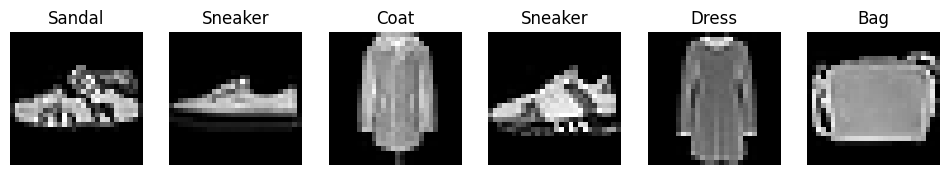

In [ ]:
labels_map = {
    0: "T-Shirt", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle Boot"
}

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for idx in range(6):
    ax = axes[idx]
    # Unnormalize image for visualization
    img = images[idx].squeeze() / 2 + 0.5
    ax.imshow(img.numpy(), cmap="gray")
    ax.set_title(labels_map[labels[idx].item()])
    ax.axis("off")
plt.show()

---
## 4. Interactive Exercise: Building a Simple CNN

Let's build our network step-by-step using `nn.Module`.

### Calculating Feature Shapes:
1. **Input**: Tensor shape `(Batch, 1, 28, 28)` (1 grayscale channel, $28 \times 28$ size).
2. **Conv1** (`in_channels=1, out_channels=16, kernel_size=3, padding=1`): Maintains shape `(16, 28, 28)`.
3. **MaxPool2d** (`kernel_size=2, stride=2`): Cuts spatial size in half $\rightarrow$ `(16, 14, 14)`.
4. **Conv2** (`in_channels=16, out_channels=32, kernel_size=3, padding=1`): Output shape `(32, 14, 14)`.
5. **MaxPool2d** (`kernel_size=2, stride=2`): Cuts spatial size in half $\rightarrow$ `(32, 7, 7)`.
6. **Flatten**: Reshapes `(32, 7, 7)` into a 1D vector of size $32 \times 7 \times 7 = 1568$.
7. **Linear**: Maps $1568 \rightarrow 10$ classes.

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()

        # Layer 1: Convolutional block
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Layer 2: Convolutional block
        # TODO Challenge 2: Fill in the missing channels for Conv2
        # Hint: input channels should match output channels of conv1 (16)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)  # FIXME: fill in channels
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully connected layer
        # TODO Challenge 3: Calculate the input dimension after flattening (32 * 7 * 7)
        flattened_dim = 32 * 7 * 7  # FIXME: Replace with number
        self.fc = nn.Linear(in_features=flattened_dim, out_features=10)

    def forward(self, x):
        # Forward pass through Conv1 block
        x = self.pool1(self.relu1(self.conv1(x)))

        # Forward pass through Conv2 block
        x = self.pool2(self.relu2(self.conv2(x)))

        # Flatten the feature maps
        x = x.view(x.size(0), -1)

        # Output logits
        x = self.fc(x)
        return x

# Instantiate model and transfer to device
model = SimpleCNN().to(device)
print(model)

---
## 5. Training the Model

Now we'll define:
- **Loss Function**: `nn.CrossEntropyLoss()` for multi-class classification.
- **Optimizer**: `optim.Adam()` to update network parameters.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train(model, dataloader, criterion, optimizer, epochs=5):
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (inputs, targets) in enumerate(dataloader):
            inputs, targets = inputs.to(device), targets.to(device)

            # 1. Clear zero gradients
            optimizer.zero_grad()

            # 2. Forward pass
            outputs = model(inputs)

            # 3. Compute loss
            loss = criterion(outputs, targets)

            # TODO Challenge 4: Fill in the backward pass call and optimizer step
            loss.backward()      # FIXME: Call backward computation
            optimizer.step()     # FIXME: Call optimizer step

            # Track metrics
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

        epoch_loss = running_loss / len(dataloader)
        epoch_acc = 100. * correct / total
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

# Start Training!
train(model, train_loader, criterion, optimizer, epochs=5)

---
## 6. Evaluation and Testing

Let's test our trained model on previously unseen test images.

In [ ]:
def evaluate(model, dataloader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

    accuracy = 100. * correct / total
    print(f"Test Accuracy: {accuracy:.2f}%")

evaluate(model, test_loader)

### Visualizing Predictions
Let's view sample predictions along with their ground truth labels.

In [ ]:
model.eval()
dataiter = iter(test_loader)
images, labels = next(dataiter)

outputs = model(images.to(device))
_, preds = torch.max(outputs, 1)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for idx in range(10):
    ax = axes[idx // 5, idx % 5]
    img = images[idx].squeeze() / 2 + 0.5
    ax.imshow(img.numpy(), cmap="gray")
    true_label = labels_map[labels[idx].item()]
    pred_label = labels_map[preds[idx].item()]
    color = "green" if true_label == pred_label else "red"
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)
    ax.axis("off")
plt.tight_layout()
plt.show()

---
## 🎓 Next Steps & Experiments
1. **Add a 3rd Conv Layer:** Try adding another convolutional block to `SimpleCNN` and see how accuracy changes.
2. **Experiment with Hyperparameters:** Change learning rate or batch size to see their impact on training speed.
3. **Try Dropout:** Add `nn.Dropout(0.25)` after pooling layers to reduce overfitting.